### 1. Setup and loading

In [2]:
import sys                    
sys.path.append("..")           

import numpy as np               
import pandas as pd              
import matplotlib.pyplot as plt  

from sklearn.linear_model import LinearRegression, Ridge, Lasso, LassoCV  # regression models
from sklearn.model_selection import cross_val_score                       # cross-validation
from sklearn.preprocessing import StandardScaler                          # scaling
from sklearn.metrics import mean_squared_error, mean_absolute_error       # error measures

from src.utils import SEED, select_by_quota, recall_at_quota, within_village_auc  # code

print("SEED:", SEED)   # check that the shared seed is loaded (should be 40)

df = pd.read_pickle("../data/processed/households_clean.pkl")        # clean households from 01
test_villages = pd.read_csv("../data/processed/test_villages.csv")   # the 128 test villages
cv_folds = pd.read_csv("../data/processed/cv_folds.csv")             # 512 train villages and fold number


SEED: 40


### 2. Features (X), target (Y), train and test split

In [3]:
# Feature List of Set A from 01_data_prep, without village-level variables
house  = ["pcfloor", "tfloor", "twall", "troof", "toilet",
          "water", "lighting", "fcook", "house"]         
hh     = ["hhsize", "hhsize2", "age04", "eschild",
          "jschild", "sschild", "depratio"]            
head   = ["hhage", "hhage2", "hhmale", "hhmarried",
          "hhmalemarr", "hheduc2", "hheduc3", "hheduc4",
          "hhsector1", "hhsector2", "hhsector3",
          "formal", "informal"]                        # household head
educ   = ["higheduc2", "higheduc3", "higheduc4"]       # highest education in household
credit = ["credit"]                                      
assets = ["se2_17", "se2_11_12", "se2_125", "se2_126_127",
          "se2_119", "se2_117", "se2_115", "se2_13_15",
          "se2_14", "se2_114", "se2_18", "se2_124",
          "se2_122_123", "se5_110", "se5_11_12",
          "se5_15_16", "se2_138"]                # assets in the gov. formula
flags  = ["hheduc_missing", "no_workingage",
          "pcfloor_missing"]                     # missing-value flags from 01

features = house + hh + head + educ + credit + assets + flags  # all features in one list
target = "LOGCONSUMPTION"                                      # what we predict

print("number of features:", len(features)) 


number of features: 53


In [4]:
# Split into train and test villages
is_test = df["hhea"].isin(test_villages["hhea"])   # true if the household lives in a test village
train = df.loc[~is_test].copy()                    # not training households
test  = df.loc[is_test].copy()                     # test households

print("train:", train.shape, "| villages:", train["hhea"].nunique())   # rows, columns, villages
print("test: ", test.shape, "| villages:", test["hhea"].nunique())
print("no village in both:", set(train["hhea"]).isdisjoint(test["hhea"]))   # must be True


train: (4090, 112) | villages: 512
test:  (1023, 112) | villages: 128
no village in both: True


**Why we split by village:** The model will be used in new villages. Households in one village share prices, roads and jobs. If neighbours were in both train and test, the test score would look too good. So we use the 128 test villages from 01_data_prep, and no village is in both parts.

In [5]:
# Features (X) and target (y) for train and test
X_train = train[features].astype(float)   # features as decimal numbers (<NA> becomes NaN)
X_test  = test[features].astype(float)    # same columns for test
y_train = train[target]                   # target for training
y_test  = test[target]                    # target for testing (used only at the end!)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)   # rows, columns
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)
display(X_train.head())                   # first 5 training households

na = X_train.isna().sum()                 # missing values per column (train)
print(na[na > 0])                         # only columns with missing values

X_train: (4090, 53) | y_train: (4090,)
X_test:  (1023, 53) | y_test:  (1023,)


,pcfloor,tfloor,twall,troof,toilet,water,lighting,fcook,house,hhsize,...,se2_18,se2_124,se2_122_123,se5_110,se5_11_12,se5_15_16,se2_138,hheduc_missing,no_workingage,pcfloor_missing
0,24.75,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,4.0,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,10.00,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,8.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,22.50,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,4.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,28.50,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,2.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,60.00,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


pcfloor         42
toilet           7
water            1
depratio       177
hhage            4
hhage2           4
se2_122_123      4
se5_110          1
dtype: int64


### 3. Missing values: fill with the training median

The regression models cannot work with missing values, so we fill every gap with the **median of the training data**.
- **Why not delete these households?** We would lose about 6% of the training data. Also, in real life the government must rank every household, even if one answer is missing.
- **Why the median and not the mean?** Some features are very skewed. The median shows the typical household.
- **Why only the training median?** The test villages stand for new villages. If I used them to compute the median, information from the test set would leak into the model. 

In [6]:
# Fill missing values with the training median
medians = X_train.median()              # median of each feature, from TRAINING data only
X_train = X_train.fillna(medians)       # fill gaps in train with the train medians
X_test  = X_test.fillna(medians)        # fill gaps in test with the SAME train medians

print(medians[na[na > 0].index])        # the medians used for the columns that had gaps
print("missing left in train:", X_train.isna().sum().sum())   # should be 0
print("missing left in test: ", X_test.isna().sum().sum())    # should be 0

pcfloor          16.799999
toilet            1.000000
water             1.000000
depratio          0.500000
hhage            46.000000
hhage2         2116.000000
se2_122_123       1.000000
se5_110           0.000000
dtype: float64
missing left in train: 0
missing left in test:  0


### 4. Scaling

The features are measured in very different units: floor area in m², age squared in thousands, assets as 0/1. Scaling puts them all on the same scale (mean 0, standard deviation 1).
- **Why it matters for Ridge and Lasso:** they punish large coefficients. A coefficient's size depends on the unit of its feature. Without scaling, a feature measured in small numbers would get a big coefficient and be punished more, only because of its unit. After scaling, the penalty is fair to every feature.
- **For OLS** scaling does not change the predictions. But it makes the coefficients comparable: each one shows the effect of one standard deviation more of that feature.
- **Why fit on train only:** the scaler learns a mean and a standard deviation. Like the medians, these must come from the training data only, otherwise information from the test villages leaks in.
- The target `LOGCONSUMPTION` is not scaled, so the predictions stay in log consumption.

In [7]:
# Scale the features to mean 0 and standard deviation 1
scaler = StandardScaler().set_output(transform="pandas")   # scaler that gives back a DataFrame
scaler.fit(X_train)                                        # learn mean and std of each feature on TRAIN only
X_train_s = scaler.transform(X_train)                      # scale train
X_test_s  = scaler.transform(X_test)                       # scale test with the SAME train mean and std

cols = ["pcfloor", "hhsize", "hhage2", "toilet"]           # a few example features
print("train before scaling:")
display(X_train[cols].agg(["mean", "std"]).round(2))       # original units
print("train after scaling:")
display(X_train_s[cols].agg(["mean", "std"]).round(2))     # mean 0, std 1
print("test after scaling:")
display(X_test_s[cols].agg(["mean", "std"]).round(2))      # close to 0 and 1, not exact

train before scaling:


,pcfloor,hhsize,hhage2,toilet
mean,24.52,4.35,2498.99,0.65
std,29.05,1.94,1484.05,0.48


train after scaling:


,pcfloor,hhsize,hhage2,toilet
mean,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0


test after scaling:


,pcfloor,hhsize,hhage2,toilet
mean,-0.04,-0.06,-0.01,0.06
std,0.86,0.99,0.97,0.98


**Result:**
- Before scaling, the features have very different sizes: `hhage2` has a mean of about 2,500, `pcfloor` about 25, `toilet` about 0.65.
- After scaling, every training feature has mean 0 and standard deviation 1.
- In the test set the values are close to 0 and 1, but not exactly (e.g. `pcfloor` std 0.86). This is correct: the scaler learned from train only, and the test villages are slightly different. If the test were exactly 0 and 1, it would mean I had used the test data to learn the scaler.

### 5. OLS (linear regression without penalty)

In [8]:
# Fold number for every training household (folds from 01_data_prep; pd.merge as in class "Data Handling")
train_folds = pd.merge(train[["hhea"]], cv_folds, how="left", on="hhea")   # add the fold of each household's village
fold = train_folds["fold"].to_numpy()                                       # fold numbers (0-4) as an array

print(train_folds["fold"].value_counts().sort_index())    # households per fold
print("missing fold:", train_folds["fold"].isna().sum())   # should be 0
print("same order as train:", (train_folds["hhea"].to_numpy() == train["hhea"].to_numpy()).all())   # must be True

# Make the 5 splits by hand, so every model uses exactly our village folds
# (in class: cv = KFold(n_splits=5, shuffle=True). KFold would mix households of one village, so we give the folds ourselves)
splits = []                                       # list of (training rows, validation rows)
for k in range(5):                                # each fold is the validation part once
    train_idx = np.where(fold != k)[0]            # rows of the other 4 folds -> training
    val_idx = np.where(fold == k)[0]              # rows of fold k -> validation
    splits.append((train_idx, val_idx))
    print(f"fold {k}: train {len(train_idx)} | validation {len(val_idx)}")

fold
0    822
1    822
2    815
3    815
4    816
Name: count, dtype: int64
missing fold: 0
same order as train: True
fold 0: train 3268 | validation 822
fold 1: train 3268 | validation 822
fold 2: train 3275 | validation 815
fold 3: train 3275 | validation 815
fold 4: train 3274 | validation 816


In [9]:
# Cross-validation error of OLS (as in class "Cross-Validation and Model Selection")
ols = LinearRegression()                                       # OLS model, no penalty
cv_score = cross_val_score(ols, X_train_s, y_train, cv=splits,
                           scoring="neg_mean_squared_error")   # negative MSE, one per fold
ols_cv_mse = -np.mean(cv_score)                                # flip the sign, average over the 5 folds

print("MSE per fold:", (-cv_score).round(4))                   # error in each validation fold
print(f"OLS CV MSE:  {ols_cv_mse:.4f}")                        # average error
print(f"OLS CV RMSE: {np.sqrt(ols_cv_mse):.4f}")               # same, in log-consumption units
print(f"MSE if I always guess the mean: {y_train.var():.4f}")  # simple reference

MSE per fold: [0.2402 0.2103 0.2571 0.2422 0.2197]
OLS CV MSE:  0.2339
OLS CV RMSE: 0.4836
MSE if I always guess the mean: 0.4549


In [10]:
# Fit OLS on all training households and look at the coefficients (as in class "Linear Regression")
ols.fit(X_train_s, y_train)                                     # learn one weight per feature
ols_coefs = pd.Series(ols.coef_, index=features)                # coefficients with the feature names

print(f"intercept: {ols.intercept_:.3f}")                       # prediction for an average household
print(f"mean of y_train: {y_train.mean():.3f}")                 # same number, because X is scaled to mean 0
top = ols_coefs.abs().sort_values(ascending=False).index[:10]   # names of the 10 largest coefficients (by size)
display(ols_coefs.loc[top].round(3))                            # show them with their sign

intercept: 6.062
mean of y_train: 6.062


hhsize        -0.588
hhsize2        0.350
pcfloor        0.079
hhage2        -0.077
se2_117        0.075
se2_125        0.071
se2_126_127    0.067
fcook          0.066
se2_119        0.063
hhage          0.061
dtype: float64

### 6. Ridge and Lasso

Ridge and Lasso are OLS plus a penalty for large coefficients The alpha sets how strong the penalty is.
- Ridge punishes the squared coefficients. It makes all of them smaller, but none becomes exactly 0. This helps when features carry similar information (e.g. `hhage` and `hhage2`, or `hhmale` and `hhmalemarr`). OLS can then give them large opposite weights, and Ridge calms this down.
- Lasso punishes the absolute size of the coefficients. It can set some of them exactly to 0, so it also chooses features.
- alpha = 0 is plain OLS. A very large alpha pushes all coefficients to 0, and the model only predicts the mean.

In [11]:
# Penalty strengths to try
alphas = np.logspace(-3, 3, 100)    # 100 values from 0.001 to 1000, evenly spread on a log scale (as in class)

print(alphas[:3].round(4), "...", alphas[-3:].round(1))   # first and last values

[0.001  0.0011 0.0013] ... [ 756.5  869.7 1000. ]


#### Ridge
For each alpha, we compute the CV error with the same 5 village folds. Then we pick the alpha with the lowest error.

In [12]:
# Ridge: CV error for every alpha (loop by hand, as in class "Cross-Validation and Model Selection", Task 4)
ridge_scores = []                                            # CV MSE for each alpha
for alpha in alphas:                                         # try each alpha
    ridge_model = Ridge(alpha=alpha)                         # Ridge with this penalty
    cv_score = cross_val_score(ridge_model, X_train_s, y_train, cv=splits,
                               scoring="neg_mean_squared_error")   # same village folds as OLS
    ridge_scores.append(-np.mean(cv_score))                  # flip the sign, save the average MSE

best_alpha_ridge = alphas[np.argmin(ridge_scores)]           # alpha with the lowest CV error
best_score_ridge = np.min(ridge_scores)                      # that lowest CV error

print(f"Best alpha: {best_alpha_ridge:.3f}")
print(f"Ridge CV MSE: {best_score_ridge:.5f} | OLS CV MSE: {ols_cv_mse:.5f}")

Best alpha: 3.765
Ridge CV MSE: 0.23386 | OLS CV MSE: 0.23389


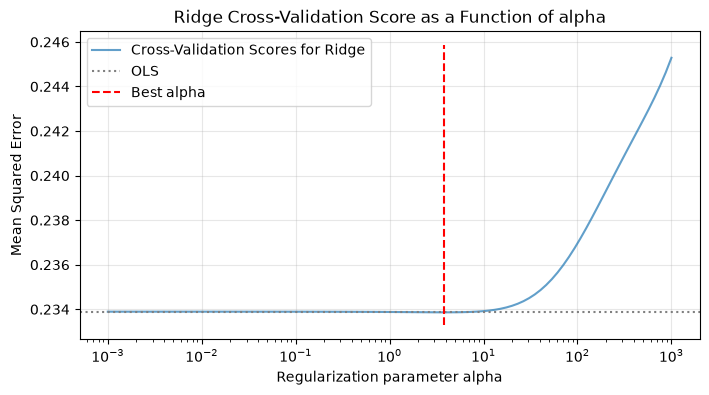

In [21]:
# Plot: Ridge CV error for each alpha (plot style as in class "Cross-Validation and Model Selection")
fig, ax = plt.subplots(figsize=(8, 4))

# CV error for each alpha that was tried
ax.plot(alphas, ridge_scores,alpha=0.7, label="Cross-Validation Scores for Ridge")
# OLS for comparison
ax.axhline(ols_cv_mse, color="grey", linestyle=":", label="OLS")
# The chosen alpha
ax.vlines(best_alpha_ridge, ax.get_ylim()[0], ax.get_ylim()[1], linestyle="--", color="red", label="Best alpha")

# Aesthetics
ax.set_xscale("log")                                   # alphas are spread on a log scale
ax.set_xlabel("Regularization parameter alpha")
ax.set_ylabel("Mean Squared Error")
ax.set_title("Ridge Cross-Validation Score as a Function of alpha")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [14]:
# Fit Ridge with the best alpha on all training households
ridge = Ridge(alpha=best_alpha_ridge)                    # Ridge with the chosen penalty
ridge.fit(X_train_s, y_train)                            # learn the coefficients
ridge_coefs = pd.Series(ridge.coef_, index=features)     # coefficients with feature names

compare = pd.DataFrame({"OLS": ols_coefs, "Ridge": ridge_coefs})   # side by side
display(compare.loc[top].round(3))                                 # same 10 features as in the OLS table

,OLS,Ridge
hhsize,-0.588,-0.571
hhsize2,0.350,0.335
pcfloor,0.079,0.080
hhage2,-0.077,-0.068
se2_117,0.075,0.075
se2_125,0.071,0.070
se2_126_127,0.067,0.067
fcook,0.066,0.066
se2_119,0.063,0.063
hhage,0.061,0.052


**Result:**
- The best alpha is about 3.765. Its CV MSE (0.23386) is almost the same as OLS (0.23389).
- On the plot, the Ridge line is flat for small alphas and goes up only for large alphas. So a little penalty does not hurt, but it does not help either.
- The Ridge coefficients are almost the same as the OLS ones, only slightly smaller. The biggest change is in pairs of similar features (`hhage` and `hhage2`, `hhsize` and `hhsize2`). This is because Ridge shares the weight between similar features.

#### Lasso

In [22]:
# Lasso: LassoCV tries every alpha with cross-validation (as in class "Cross-Validation and Model Selection")
lasso = LassoCV(alphas=alphas, cv=splits)        # same alphas and same village folds as Ridge
lasso.fit(X_train_s, y_train)                    # finds the best alpha, then refits on all training households with it

lasso_scores = lasso.mse_path_.mean(axis=1)      # CV MSE for each alpha (mean over the 5 folds)
best_score_lasso = np.min(lasso_scores)          # lowest CV error

print(f"Best alpha: {lasso.alpha_:.3f}")
print(f"Lasso CV MSE: {best_score_lasso:.5f} | OLS CV MSE: {ols_cv_mse:.5f}")

Best alpha: 0.001
Lasso CV MSE: 0.23386 | OLS CV MSE: 0.23389


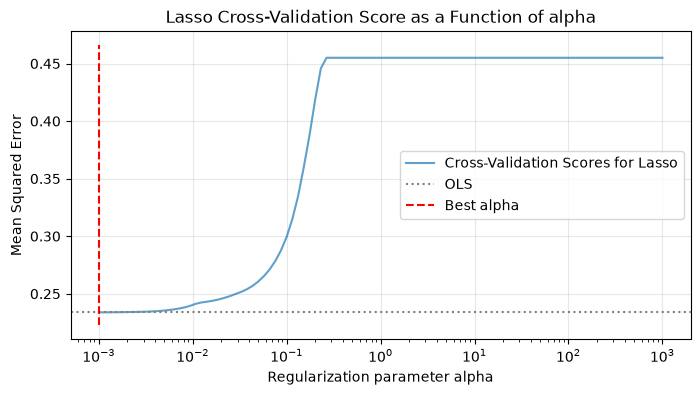

In [23]:
# Plot: Lasso CV error for each alpha (as in class "Cross-Validation and Model Selection")
fig, ax = plt.subplots(figsize=(8, 4))

# CV error for each alpha that was tried
ax.plot(lasso.alphas_, lasso_scores,
        alpha=0.7, label="Cross-Validation Scores for Lasso")
# OLS for comparison
ax.axhline(ols_cv_mse, color="grey", linestyle=":", label="OLS")
# The chosen alpha
ax.vlines(lasso.alpha_, ax.get_ylim()[0], ax.get_ylim()[1], linestyle="--", color="red", label="Best alpha")

# Aesthetics
ax.set_xscale("log")                                   # alphas are spread on a log scale
ax.set_xlabel("Regularization parameter alpha")
ax.set_ylabel("Mean Squared Error")
ax.set_title("Lasso Cross-Validation Score as a Function of alpha")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [17]:
# Which features did Lasso drop?
lasso_coefs = pd.Series(lasso.coef_, index=features)       # coefficients of the final Lasso model
zero = lasso_coefs[lasso_coefs == 0].index.tolist()         # features with coefficient exactly 0

print(f"coefficients set to 0: {len(zero)} of {len(features)}")
print(zero)                                                 # names of the dropped features
top_lasso = lasso_coefs.abs().sort_values(ascending=False).index[:10]   # 10 largest Lasso coefficients (by size)
display(lasso_coefs.loc[top_lasso].round(3))                            # show them with their sign

coefficients set to 0: 2 of 53
['hhage', 'hhsector1']


hhsize        -0.543
hhsize2        0.311
pcfloor        0.081
se2_117        0.075
se2_125        0.070
se2_126_127    0.067
fcook          0.066
se2_119        0.064
se2_18         0.055
se2_115        0.046
dtype: float64

**Result:**
- The best alpha is 0.001, the smallest value in the grid. So the less penalty, the better: Lasso wants to be almost OLS.
- On the plot, for large alphas the error goes up fast. Lasso then sets most or all coefficients to 0 and only predicts the mean.
- Lasso sets only 2 of 53 coefficients to 0: `hhage` and `hhsector1`. `hhage` is dropped, but `hhage2` (age squared) stays. The two carry almost the same information, so Lasso keeps only one.
- The largest coefficients are the same as in OLS, only a bit smaller.

#### Comparison of OLS, Ridge and Lasso (cross-validation)

In [24]:
# Compare the CV errors of the three models (table as in class "Cross-Validation and Model Selection", Task 5)
cv_results = pd.DataFrame({
    "Model":  ["OLS", "Ridge", "Lasso"],                           # model names
    "alpha":  [0, best_alpha_ridge, lasso.alpha_],                 # chosen penalty (OLS = no penalty)
    "CV MSE": [ols_cv_mse, best_score_ridge, best_score_lasso],    # average CV error
}).set_index("Model").sort_values("CV MSE")                        # lowest error first
cv_results["CV RMSE"] = np.sqrt(cv_results["CV MSE"])              # error in log-consumption units

display(cv_results.round(5))                                       # 5 decimals, the differences are tiny

,alpha,CV MSE,CV RMSE
Model,,,
Lasso,0.00100,0.23386,0.48359
Ridge,3.76494,0.23386,0.48359
OLS,0.00000,0.23389,0.48362
